--- Infrastructure Planning Module ---
Choose data mode:
1. Use default network scenario
2. Enter Custom process info


Enter choice (1 or 2):  1



Using Example Network Configuration:
  Intersection_A <--> Intersection_B | Cost: 10
  Intersection_A <--> Intersection_C | Cost: 15
  Intersection_B <--> Intersection_C | Cost: 5
  Intersection_B <--> Intersection_D | Cost: 20
  Intersection_C <--> Intersection_D | Cost: 8

--- Running Prim's Algorithm ---
Selected Road: Intersection_A to Intersection_B | Cost: 10
Selected Road: Intersection_B to Intersection_C | Cost: 5
Selected Road: Intersection_C to Intersection_D | Cost: 8
Total Infrastructure Cost (Prim's): 23

--- Running Kruskal's Algorithm ---
Selected Road: Intersection_B to Intersection_C | Cost: 5
Selected Road: Intersection_C to Intersection_D | Cost: 8
Selected Road: Intersection_A to Intersection_B | Cost: 10
Total Infrastructure Cost (Kruskal's): 23


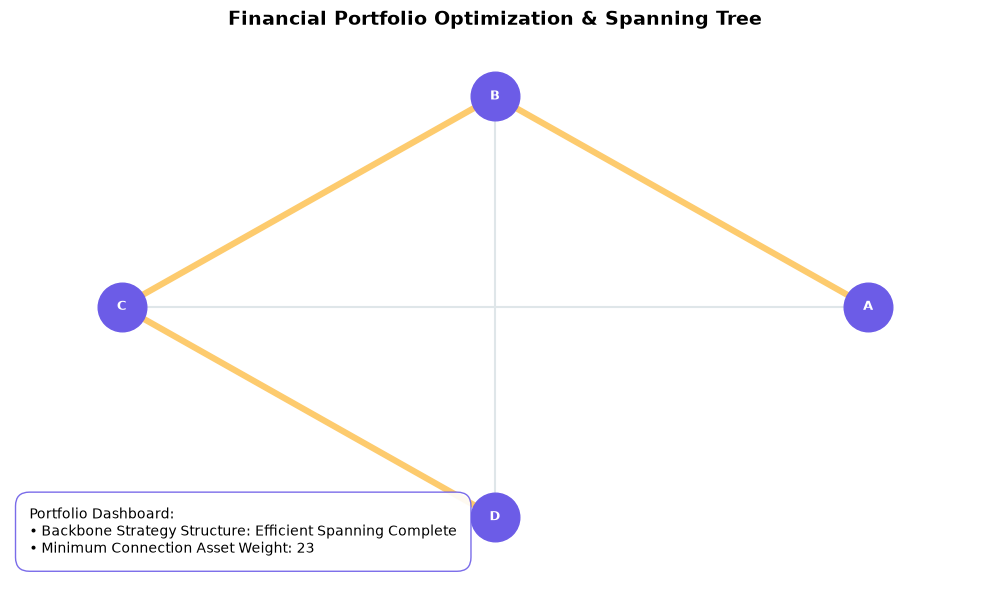

In [2]:
import sys
import heapq
import matplotlib.pyplot as plt
import math

class DisjointSet:
    def __init__(self, vertices):
        self.parent = {v: v for v in vertices}
        self.rank = {v: 0 for v in vertices}

    def find(self, item):
        if self.parent[item] == item:
            return item
        self.parent[item] = self.find(self.parent[item])
        return self.parent[item]

    def union(self, set1, set2):
        root1 = self.find(set1)
        root2 = self.find(set2)
        if root1 != root2:
            if self.rank[root1] > self.rank[root2]:
                self.parent[root2] = root1
            else:
                self.parent[root1] = root2
                if self.rank[root1] == self.rank[root2]:
                    self.rank[root2] += 1
            return True
        return False

def prims_algorithm(vertices, edges):
    if not vertices:
        return [], 0
        
    adj = {v: [] for v in vertices}
    for u, v, w in edges:
        if u in adj and v in adj:
            adj[u].append((w, v))
            adj[v].append((w, u))
    
    mst_edges = []
    total_cost = 0
    visited = set()
    
    start_vertex = vertices[0]
    min_heap = [(0, start_vertex, None)]
    
    while min_heap and len(visited) < len(vertices):
        w, u, parent = heapq.heappop(min_heap)
        
        if u in visited:
            continue
            
        visited.add(u)
        if parent is not None:
            mst_edges.append((parent, u, w))
            total_cost += w
            
        for next_w, v in adj[u]:
            if v not in visited:
                heapq.heappush(min_heap, (next_w, v, u))
                
    if len(visited) < len(vertices):
        print("\n⚠️ WARNING (Prim's): Graph is disconnected! The returned tree only covers one component.")
        
    return mst_edges, total_cost

def kruskals_algorithm(vertices, edges):
    if not vertices:
        return [], 0
        
    sorted_edges = sorted(edges, key=lambda x: x[2])
    ds = DisjointSet(vertices)
    mst_edges = []
    total_cost = 0
    
    for u, v, w in sorted_edges:
        if u in ds.parent and v in ds.parent:
            if ds.union(u, v):
                mst_edges.append((u, v, w))
                total_cost += w
                if len(mst_edges) == len(vertices) - 1:
                    break
                    
    if len(mst_edges) < len(vertices) - 1 and len(vertices) > 1:
        print("\n⚠️ WARNING (Kruskal's): Graph is disconnected! Cannot connect all intersections.")
        
    return mst_edges, total_cost

def visualize_portfolio_frontier(vertices, edges, active_mst, total_cost):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.set_title("Financial Portfolio Optimization & Spanning Tree", fontsize=14, fontweight='bold')
    
    num_nodes = len(vertices)
    pos = {}
    for idx, node in enumerate(vertices):
        angle = 2 * math.pi * idx / num_nodes
        pos[node] = (math.cos(angle), math.sin(angle))
        
    for u, v, w in edges:
        if u not in pos or v not in pos:
            continue
        x1, y1 = pos[u]
        x2, y2 = pos[v]
        
        is_on_mst = False
        if active_mst:
            for mst_u, mst_v, _ in active_mst:
                if (mst_u == u and mst_v == v) or (mst_u == v and mst_v == u):
                    is_on_mst = True
                    break
                    
        if is_on_mst:
            ecolor = '#fdcb6e'
            ewidth = 4.5
        else:
            ecolor = '#dfe6e9'
            ewidth = 1.5
            
        ax.plot([x1, x2], [y1, y2], color=ecolor, lw=ewidth)
        
    for node, (x, y) in pos.items():
        ax.plot(x, y, marker='o', markersize=35, color='#6c5ce7', linestyle='None')
        ax.text(x, y, str(node).replace("Intersection_", ""), color='white', ha='center', va='center', fontweight='bold', fontsize=9)
        
    info_text = f"Portfolio Dashboard:\n• Backbone Strategy Structure: Efficient Spanning Complete\n• Minimum Connection Asset Weight: {total_cost}"
    ax.text(0.02, 0.05, info_text, transform=ax.transAxes, 
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='#6c5ce7', boxstyle='round,pad=1'))
            
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

def main():
    print("--- Infrastructure Planning Module ---")
    print("Choose data mode:")
    print("1. Use default network scenario")
    print("2. Enter Custom process info")
    choice = input("Enter choice (1 or 2): ").strip()
    
    if choice == '2':
        try:
            vertices = input("Enter intersections separated by commas (e.g., A, B, C): ").strip().split(',')
            vertices = [v.strip() for v in vertices if v.strip()]
            if not vertices:
                print("Error: You must enter at least one intersection.")
                return
            num_edges = int(input("Enter number of roads: "))
            edges = []
            print("Enter each road line-by-line format -> Source, Destination, Cost")
            for i in range(num_edges):
                line = input(f"Road {i+1}: ").strip().split(',')
                if len(line) != 3:
                    print("Error: Input format invalid. Skipping this road.")
                    continue
                u, v, w = [item.strip() for item in line]
                edges.append((u, v, int(w)))
        except ValueError:
            print("Error: Invalid numeric input entered. Terminating.")
            return
    else:
        vertices = ["Intersection_A", "Intersection_B", "Intersection_C", "Intersection_D"]
        edges = [
            ("Intersection_A", "Intersection_B", 10),
            ("Intersection_A", "Intersection_C", 15),
            ("Intersection_B", "Intersection_C", 5),
            ("Intersection_B", "Intersection_D", 20),
            ("Intersection_C", "Intersection_D", 8)
        ]
        print("\nUsing Example Network Configuration:")
        for u, v, w in edges:
            print(f"  {u} <--> {v} | Cost: {w}")

    print("\n--- Running Prim's Algorithm ---")
    prim_mst, prim_cost = prims_algorithm(vertices, edges)
    for u, v, w in prim_mst:
        print(f"Selected Road: {u} to {v} | Cost: {w}")
    print(f"Total Infrastructure Cost (Prim's): {prim_cost}")

    print("\n--- Running Kruskal's Algorithm ---")
    kruskal_mst, kruskal_cost = kruskals_algorithm(vertices, edges)
    for u, v, w in kruskal_mst:
        print(f"Selected Road: {u} to {v} | Cost: {w}")
    print(f"Total Infrastructure Cost (Kruskal's): {kruskal_cost}")
    
    visualize_portfolio_frontier(vertices, edges, kruskal_mst, kruskal_cost)

if __name__ == "__main__":
    main()